# Deteccion de fraude en tarjetas de credito

## Objetivo
Explorar el dataset y entrenar modelos de machine learning paso a paso para identificar transacciones fraudulentas.

## Dataset
El archivo `creditcard.csv` contiene transacciones. `Time` representa el tiempo, `V1` a `V28` son variables numericas transformadas, `Amount` es el importe y `Class` es la etiqueta objetivo (0 = transaccion legitima, 1 = fraude).


## 1. Imports

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE



## 2. Carga y vista inicial
Carga el CSV y revisa algunas filas, dimensiones y tipos de datos.

In [2]:
df = pd.read_csv("creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 3. Calidad de datos
Investiga valores faltantes, duplicados, tipos y estadisticas descriptivas.

In [3]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 250)

# 1) tamaño y tipos de datos
print('Filas y columnas:', df.shape)
df.info()

# 2) duplicados
n_dup = df.duplicated().sum()
print(f'\nDuplicadas: {n_dup} ({100*n_dup/len(df):.2f}%)')


Filas y columnas: (284807, 31)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  flo

In [4]:
cols_ver = ['Time', 'V1', 'V2', 'V3', 'Amount', 'Class']   # pocas columnas para que quepa en pantalla

grupos = (df[df.duplicated(keep=False)]
          .groupby(list(df.columns)).size()
          .reset_index(name='veces')
          .sort_values('Time'))

print(len(grupos), 'grupos de duplicados')
print(grupos['veces'].value_counts())      # cuántos grupos tienen 2, 3, 4... copias
grupos[cols_ver + ['veces']].head(50)      # primeros 50

773 grupos de duplicados
veces
2     611
4      81
3      66
5      10
9       2
18      2
6       1
Name: count, dtype: int64


,Time,V1,V2,V3,Amount,Class,veces
0,26.0,-0.535388,0.865268,1.351076,1.77,0,2
1,26.0,-0.529912,0.873892,1.347247,6.14,0,2
2,74.0,1.038370,0.127486,0.184456,1.18,0,4
3,145.0,-2.420413,1.947885,0.553646,6.00,0,2
4,145.0,-2.419486,1.949346,0.552998,6.74,0,2
5,919.0,0.904289,-0.538055,0.396058,158.00,0,2
6,919.0,1.207596,-0.036860,0.572104,1.00,0,2
7,1074.0,-2.445204,-0.505494,0.164511,1.00,0,2
8,1074.0,-2.248488,-0.195670,0.026949,158.00,0,2
9,1308.0,-1.379848,0.536720,2.647870,43.80,0,2


In [5]:
print('Antes:', df.shape)
print(df['Class'].value_counts())

df = df.drop_duplicates().reset_index(drop=True)

print('Después:', df.shape)
print(df['Class'].value_counts())
print('Duplicados restantes:', df.duplicated().sum())

Antes: (284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64
Después: (283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64
Duplicados restantes: 0


## 4. EDA

In [6]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000,283726.000000
mean,94811.077600,0.005917,-0.004135,0.001613,-0.002966,0.001828,-0.001139,0.001801,-0.000854,-0.001596,-0.001441,0.000202,-0.000715,0.000603,0.000252,0.001043,0.001162,0.000170,0.001515,-0.000264,0.000187,-0.000371,-0.000015,0.000198,0.000214,-0.000232,0.000149,0.001763,0.000547,88.472687,0.001667
std,47481.047891,1.948026,1.646703,1.508682,1.414184,1.377008,1.331931,1.227664,1.179054,1.095492,1.076407,1.018720,0.994674,0.995430,0.952215,0.914894,0.873696,0.842507,0.837378,0.813379,0.769984,0.723909,0.724550,0.623702,0.605627,0.521220,0.482053,0.395744,0.328027,250.399437,0.040796
min,0.000000,-56.407510,-72.715728,-48.325589,-5.683171,-113.743307,-26.160506,-43.557242,-73.216718,-13.434066,-24.588262,-4.797473,-18.683715,-5.791881,-19.214325,-4.498945,-14.129855,-25.162799,-9.498746,-7.213527,-54.497720,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.604551,-22.565679,-15.430084,0.000000,0.000000
25%,54204.750000,-0.915951,-0.600321,-0.889682,-0.850134,-0.689830,-0.769031,-0.552509,-0.208828,-0.644221,-0.535578,-0.761649,-0.406198,-0.647862,-0.425732,-0.581452,-0.466860,-0.483928,-0.498014,-0.456289,-0.211469,-0.228305,-0.542700,-0.161703,-0.354453,-0.317485,-0.326763,-0.070641,-0.052818,5.600000,0.000000
50%,84692.500000,0.020384,0.063949,0.179963,-0.022248,-0.053468,-0.275168,0.040859,0.021898,-0.052596,-0.093237,-0.032306,0.139072,-0.012927,0.050209,0.049299,0.067119,-0.065867,-0.002142,0.003367,-0.062353,-0.029441,0.006675,-0.011159,0.041016,0.016278,-0.052172,0.001479,0.011288,22.000000,0.000000
75%,139298.000000,1.316068,0.800283,1.026960,0.739647,0.612218,0.396792,0.570474,0.325704,0.595977,0.453619,0.739579,0.616976,0.663178,0.492336,0.650104,0.523512,0.398972,0.501956,0.458508,0.133207,0.186194,0.528245,0.147748,0.439738,0.350667,0.240261,0.091208,0.078276,77.510000,0.000000
max,172792.000000,2.454930,22.057729,9.382558,16.875344,34.801666,73.301626,120.589494,20.007208,15.594995,23.745136,12.018913,7.848392,7.126883,10.526766,8.877742,17.315112,9.253526,5.041069,5.591971,39.420904,27.202839,10.503090,22.528412,4.584549,7.519589,3.517346,31.612198,33.847808,25691.160000,1.000000


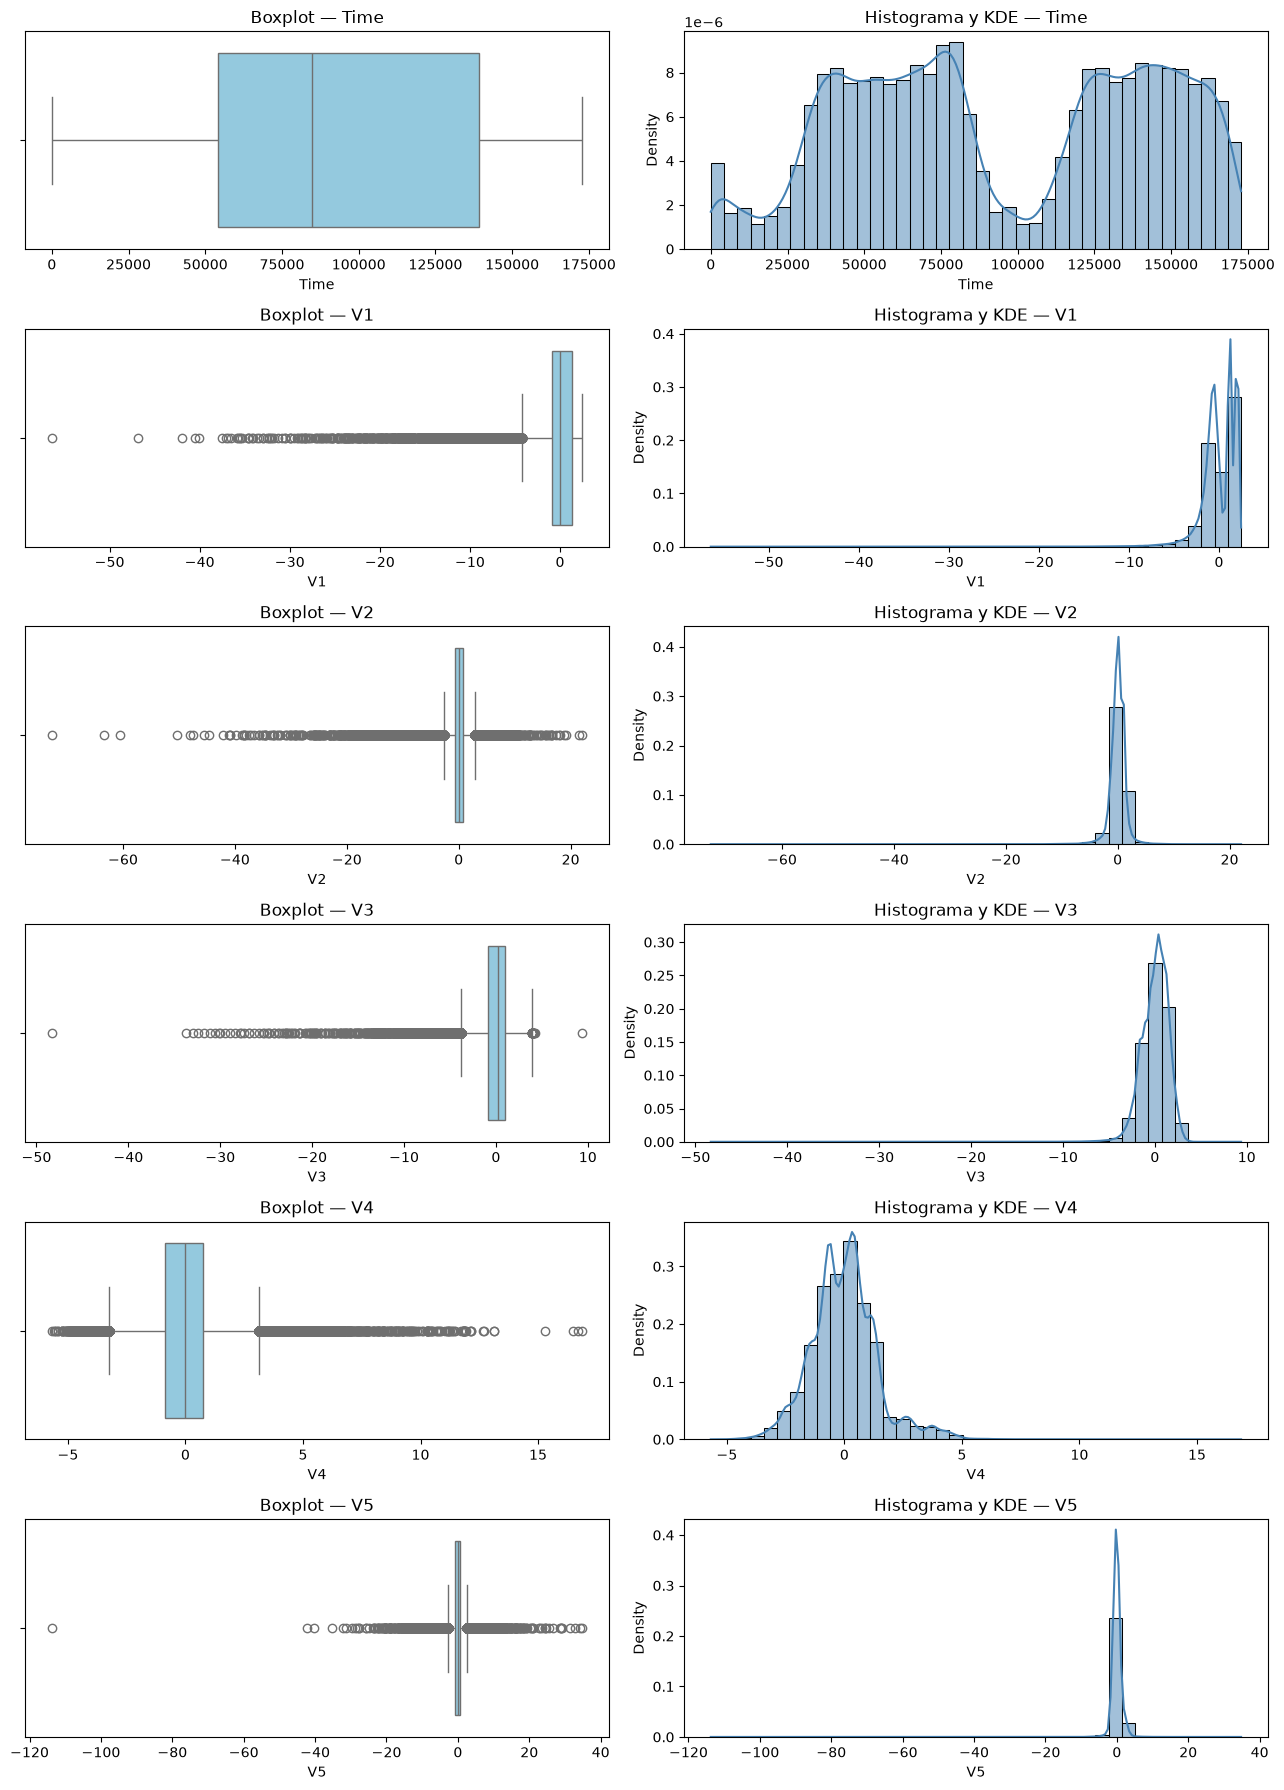

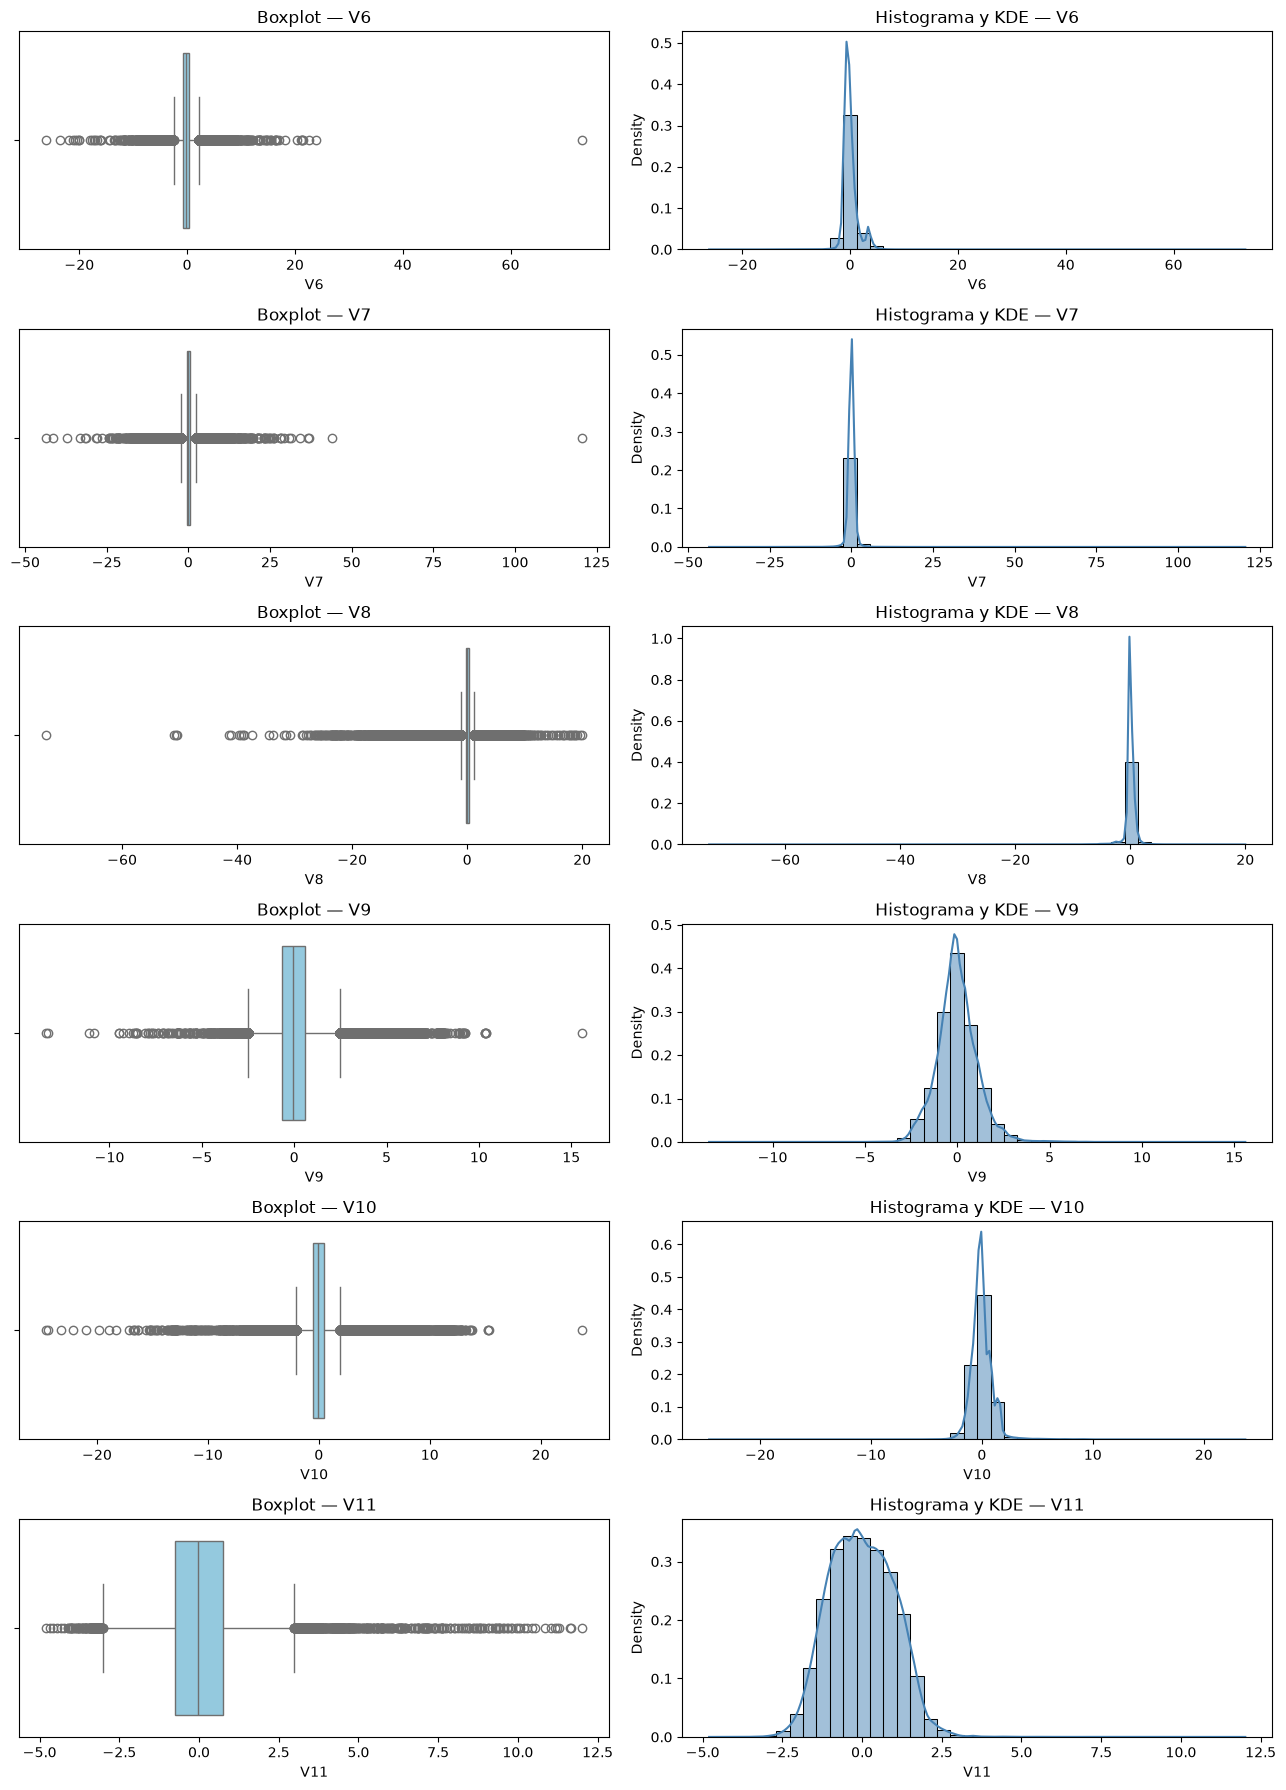

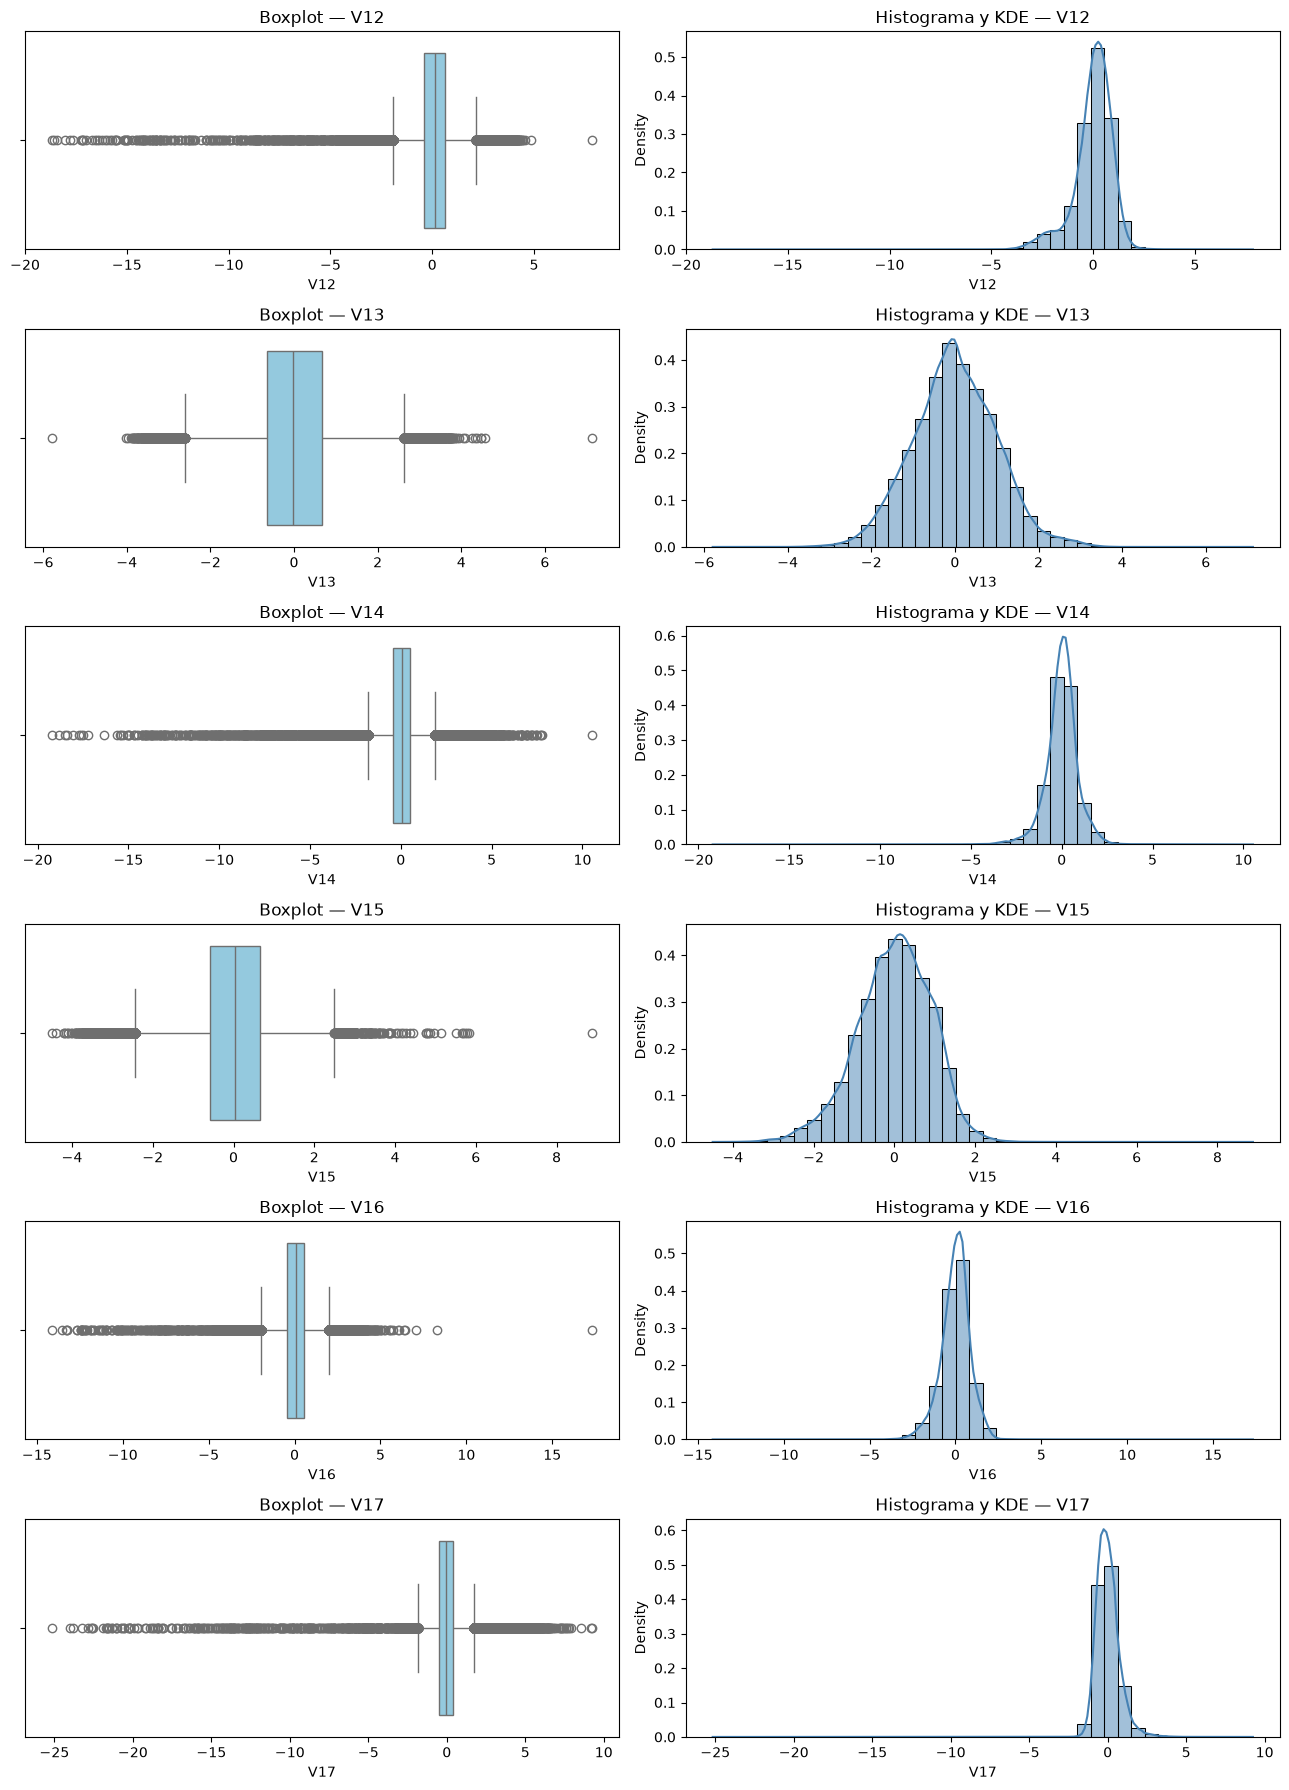

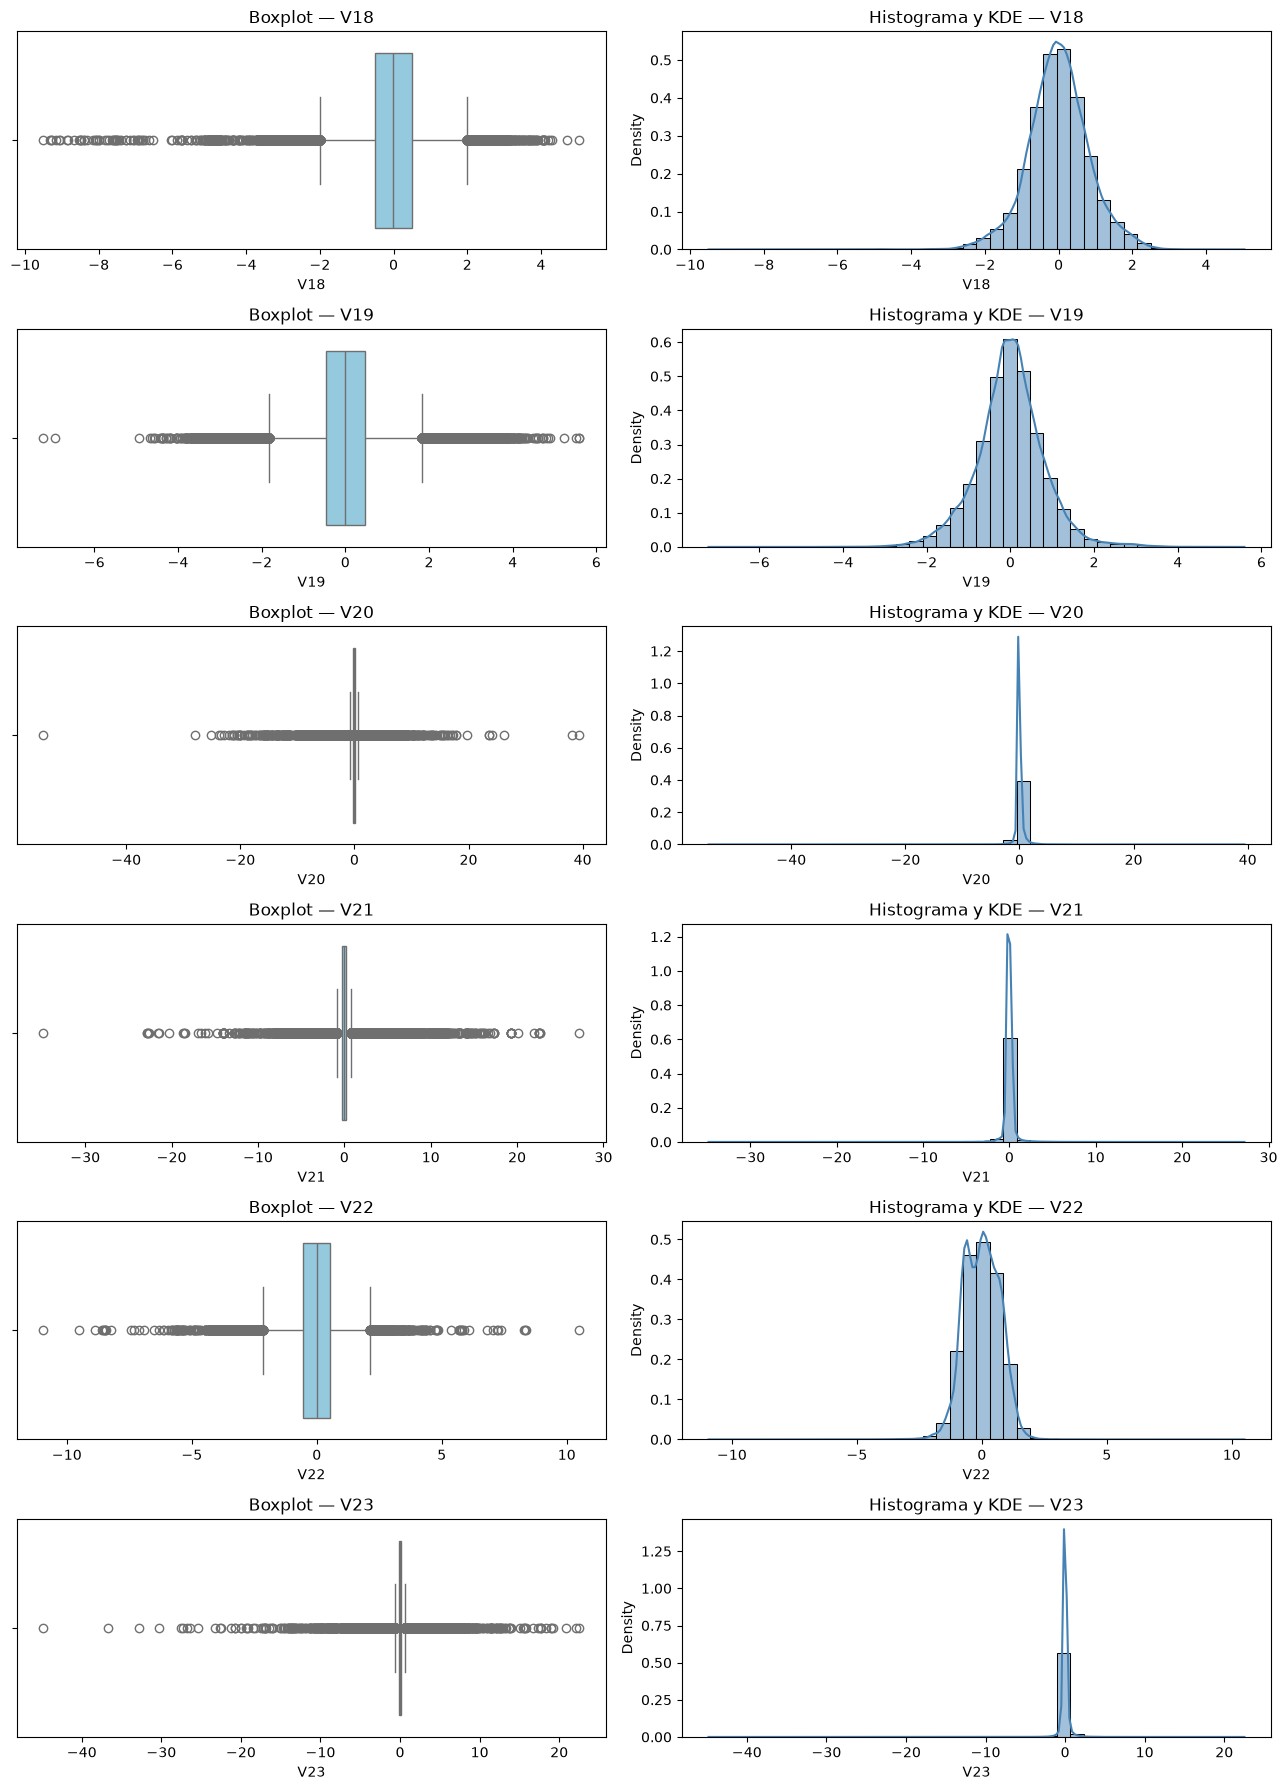

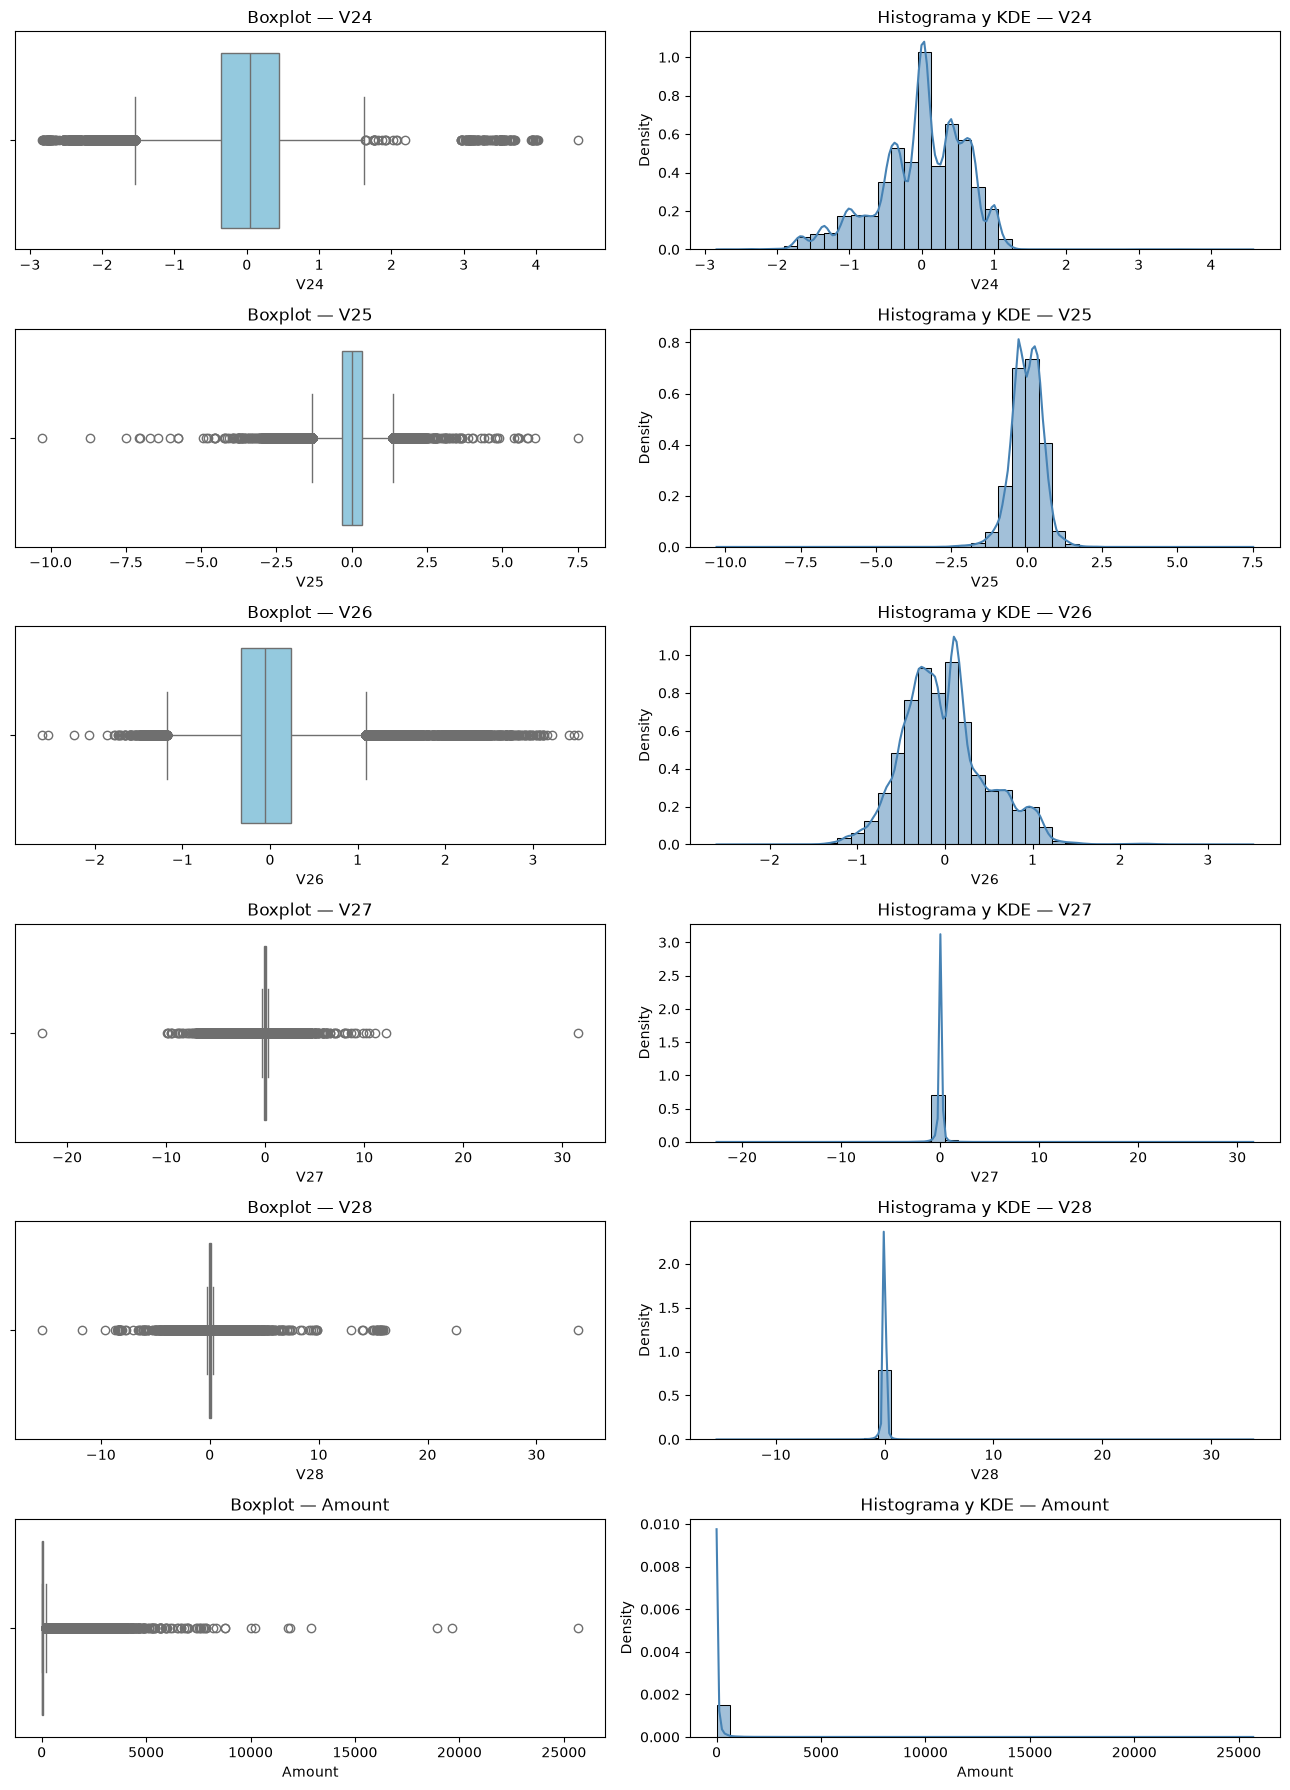

In [7]:
#Análisis univariado para cada variable
# Excluir Class: al ser una etiqueta binaria, se analizará con un gráfico de conteo.
variables = [
    columna
    for columna in df.select_dtypes(include="number").columns
    if columna != "Class"
]

for inicio in range(0, len(variables), 6):
    grupo = variables[inicio:inicio + 6]

    fig, axes = plt.subplots(
        len(grupo), 2,
        figsize=(13, 3 * len(grupo)),
        squeeze=False
    )

    for fila, variable in enumerate(grupo):
        valores = df[variable].dropna()

        # Boxplot con todos los datos disponibles.
        sns.boxplot(
            x=valores,
            ax=axes[fila, 0],
            color="skyblue"
        )
        axes[fila, 0].set_title(f"Boxplot — {variable}")
        axes[fila, 0].set_xlabel(variable)

        # Histograma y KDE con todos los datos disponibles.
        sns.histplot(
            x=valores,
            bins=40,
            stat="density",
            kde=True,
            ax=axes[fila, 1],
            color="steelblue"
        )
        axes[fila, 1].set_title(f"Histograma y KDE — {variable}")
        axes[fila, 1].set_xlabel(variable)

    plt.tight_layout()
    plt.show()
    plt.close(fig)


La mayor parte de los datos se encuentra fuera de los límites del boxplot (regla del IQR) y, aun asumiendo una distribución normal, también presenta un z-score mayor o igual a 3. Por ello, estos criterios no son adecuados para eliminar outliers en este conjunto de datos, ya que implicarían descartar la mayoría de las observaciones y se perdería gran parte de la información.

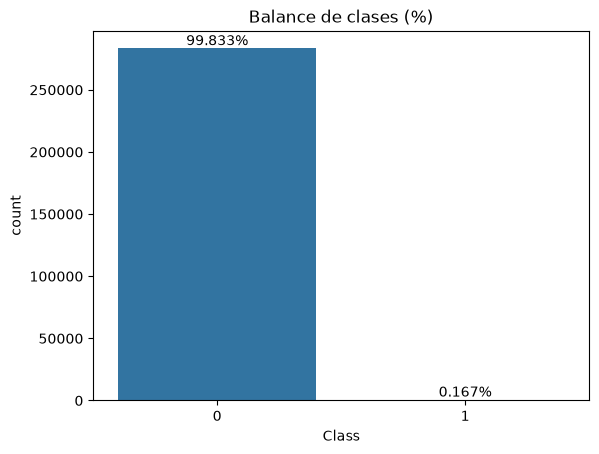

In [8]:
ax = sns.countplot(x="Class", data=df)
ax.set_title("Balance de clases (%)")

for barra in ax.patches:
    pct = barra.get_height() / len(df) * 100
    ax.annotate(f"{pct:.3f}%", (barra.get_x() + barra.get_width()/2,
                barra.get_height()), ha="center", va="bottom")

plt.show()



La variable objetivo está **fuertemente desbalanceada**: los fraudes representan aproximadamente el **0,167 %** de las transacciones.



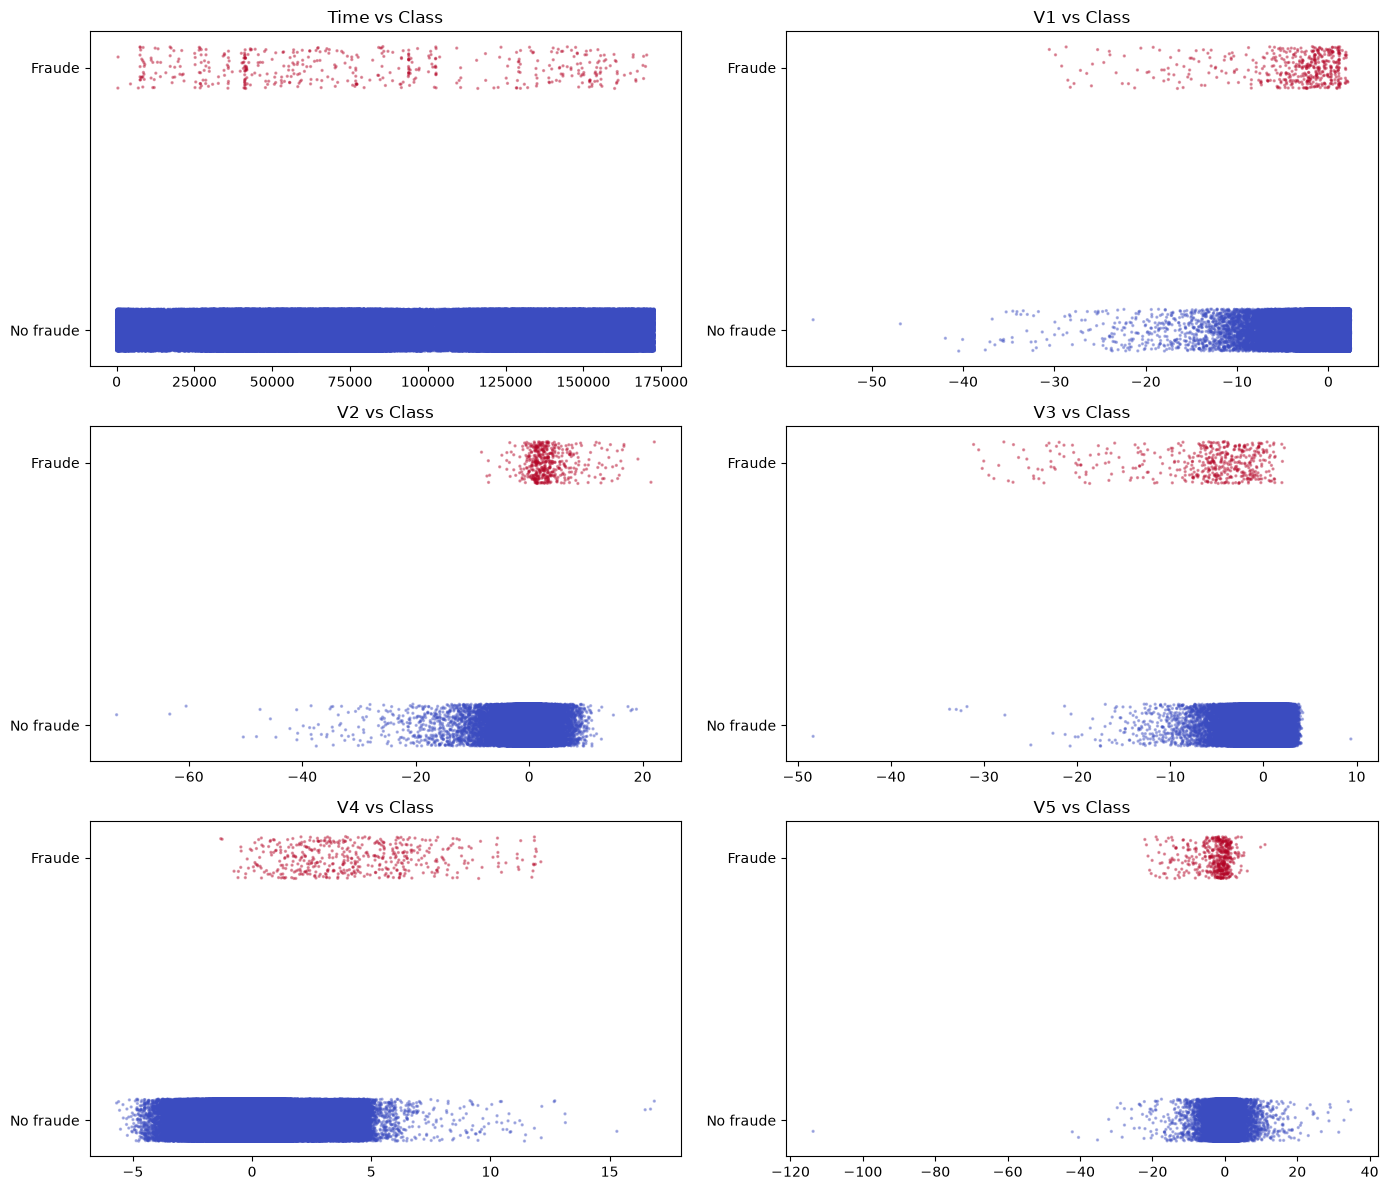

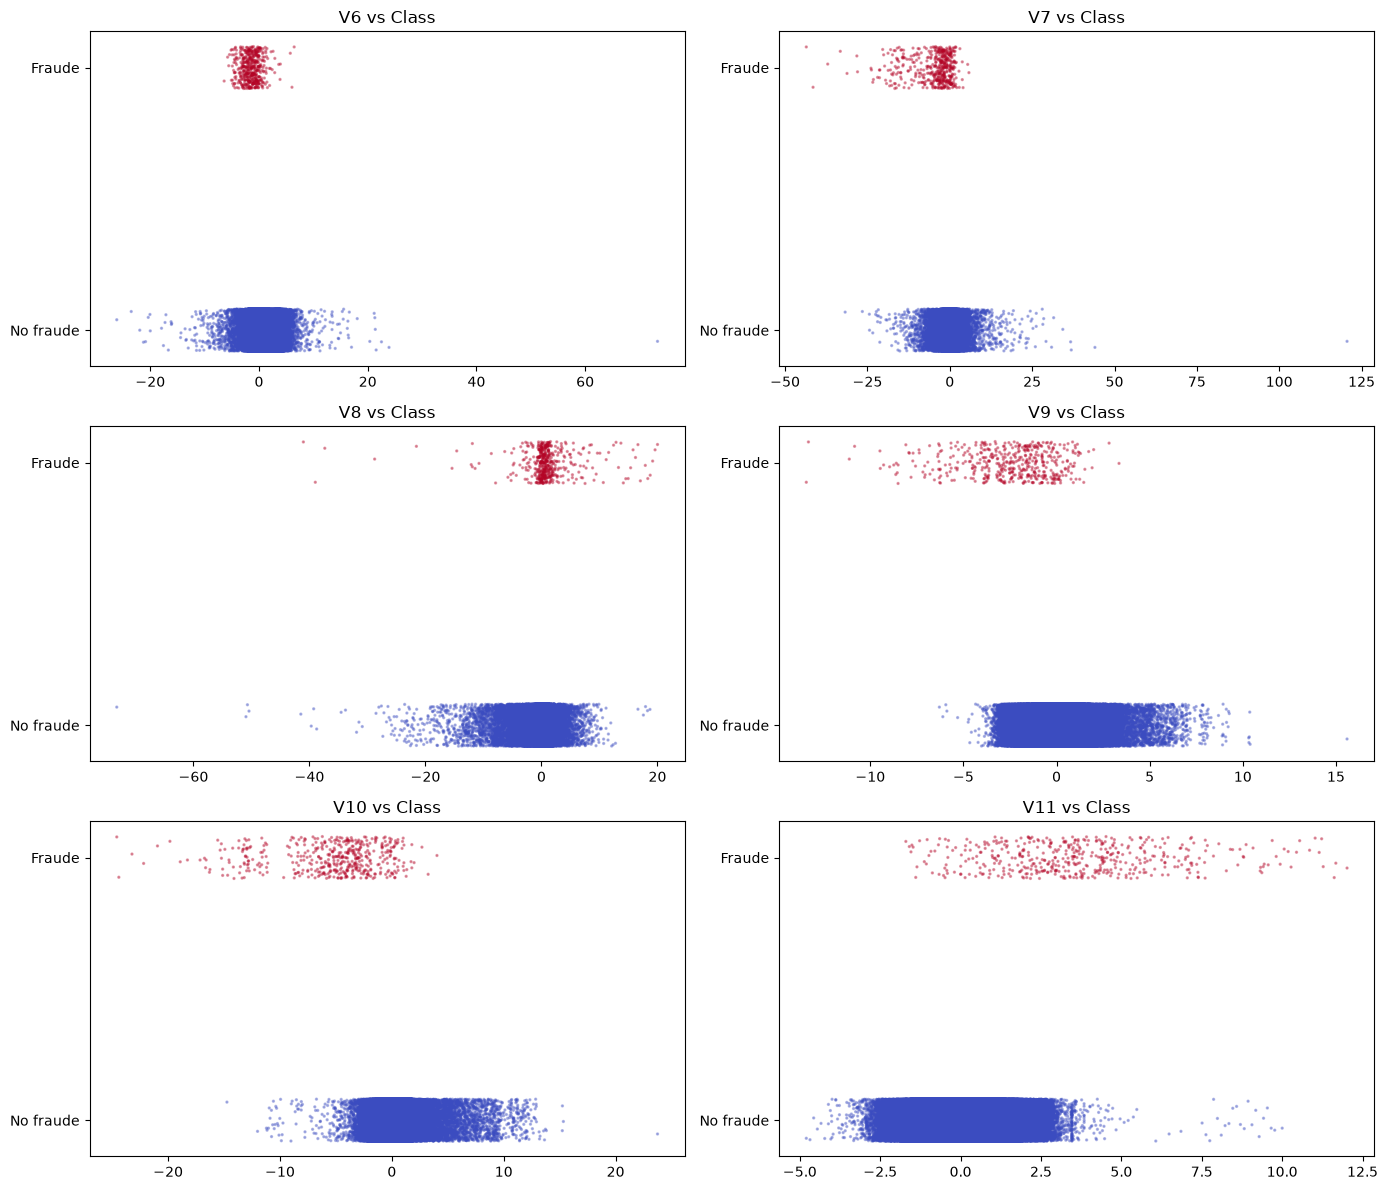

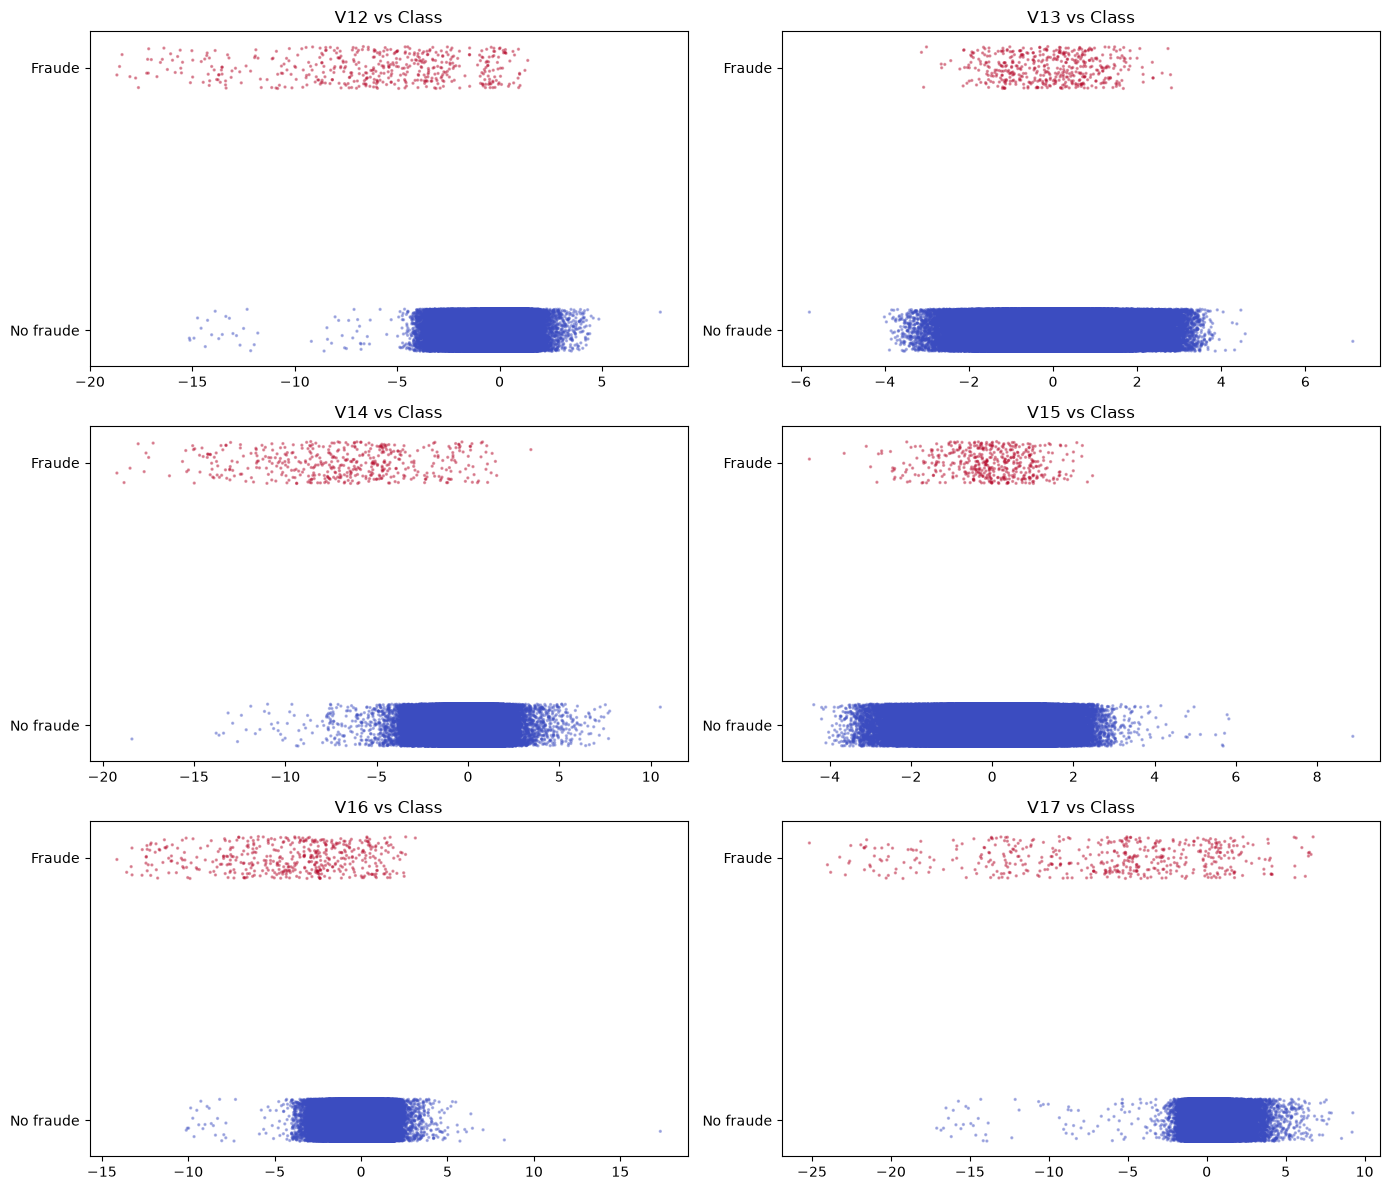

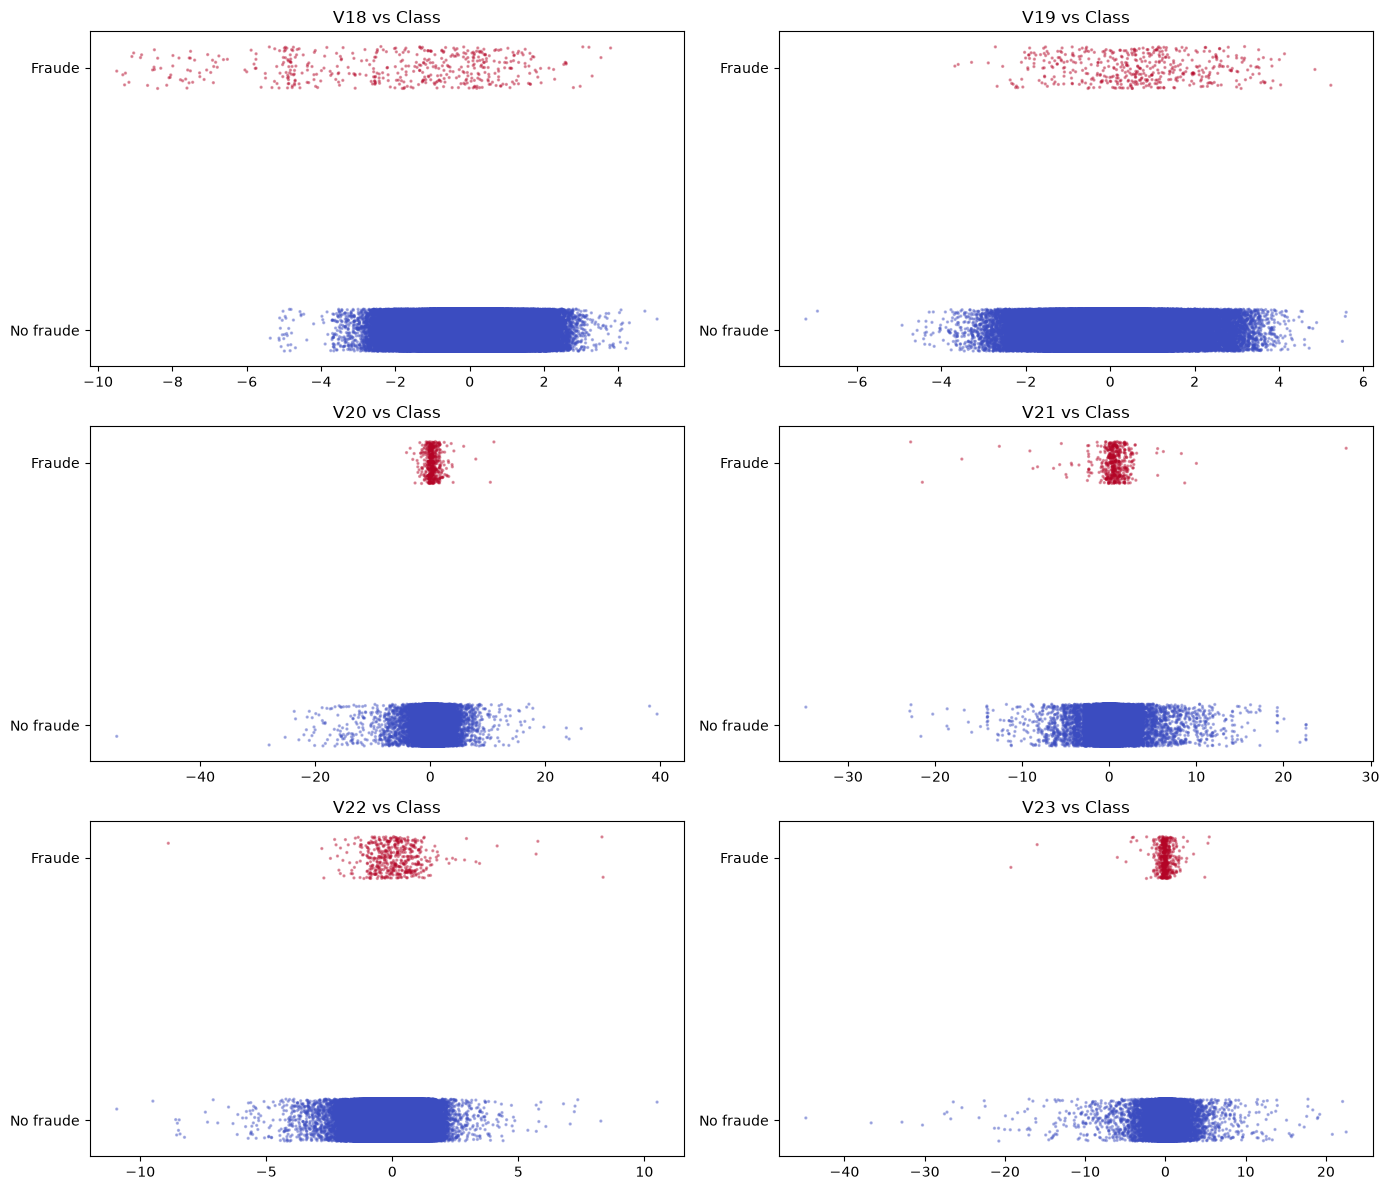

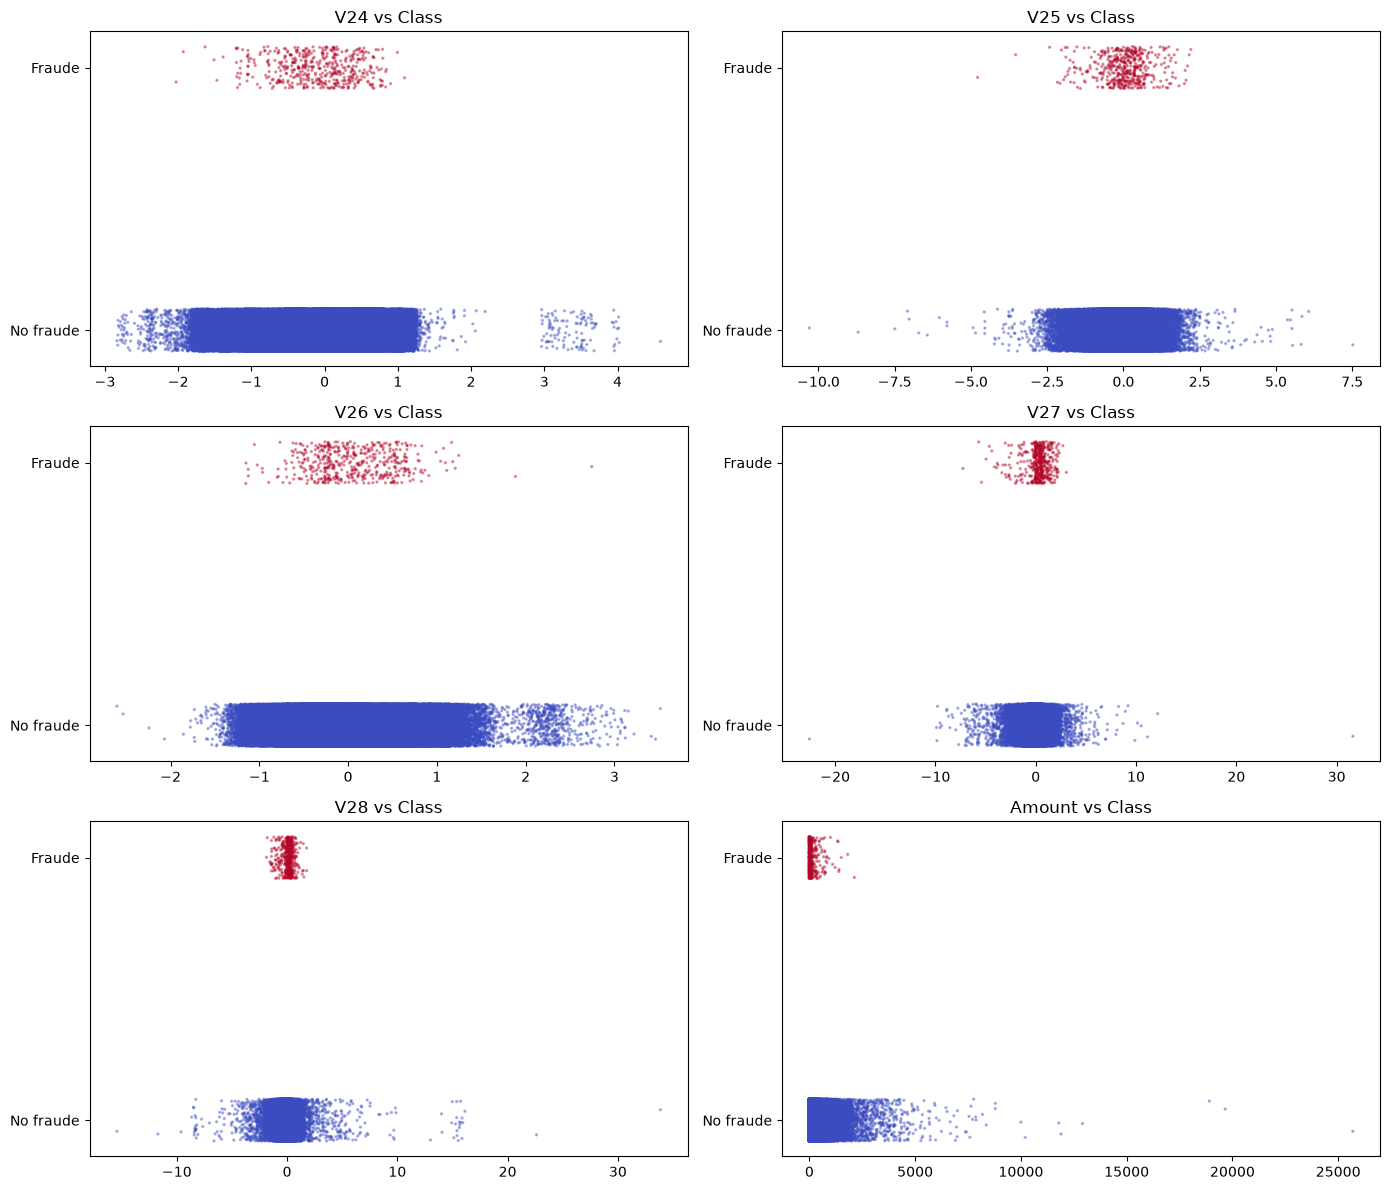

In [9]:
cols = df.columns.drop("Class")
y = df["Class"].to_numpy() + np.random.default_rng(42).uniform(-.08, .08, len(df))

for i in range(0, len(cols), 6):
    f, axes = plt.subplots(3, 2, figsize=(14, 12))
    for ax, c in zip(axes.ravel(), cols[i:i+6]):
        ax.scatter(df[c], y, c=df["Class"], cmap="coolwarm", s=2, alpha=.35, rasterized=True)
        ax.set(title=f"{c} vs Class", yticks=[0, 1], yticklabels=["No fraude", "Fraude"])
    for ax in axes.ravel()[len(cols[i:i+6]):]: ax.axis("off")
    plt.tight_layout(); plt.show(); plt.close(f)

La variable 2 muestra que, aunque gran parte de la acumulación de fraude se encuentra cerca de la de no fraude, los valores desde aproximadamente -10 hacia adelante tienden a marcar bastante los casos de fraude.

La variable 10 tampoco presenta una delimitación marcada entre fraude y no fraude. Sin embargo, desde valores cercanos a 0 hacia la izquierda se concentran más casos de fraude, por lo que esta variable podría ser útil.

En la variable 11 las clases están bastante mezcladas, pero a partir de 0 hacia la derecha el fraude se marca notablemente más que el no fraude.

En la variable 12 el no fraude se concentra claramente entre -5 y 5, mientras que el fraude ocupa solo una parte reducida de ese rango y se extiende hacia valores fuera de él.

La variable 14 muestra un comportamiento muy parecido al de la variable 12, por lo que es posible que ambas estén correlacionadas.

En la variable 17 el patrón es poco marcado entre -15 y -2.5; a partir de ahí el no fraude se concentra con claridad y el fraude disminuye.

En la variable 27 tanto el fraude como el no fraude se marcan bastante en rangos juntos. Considerando que desde 0 hacia la derecha el fraude se nota más y el no fraude se reduce ligeramente, también podría ser una variable útil.

En la variable Amount ambas clases comienzan desde valores bajos, pero el fraude tiende a concentrarse en montos pequeños, mientras que el no fraude se extiende y se dispara hacia montos mucho más altos.

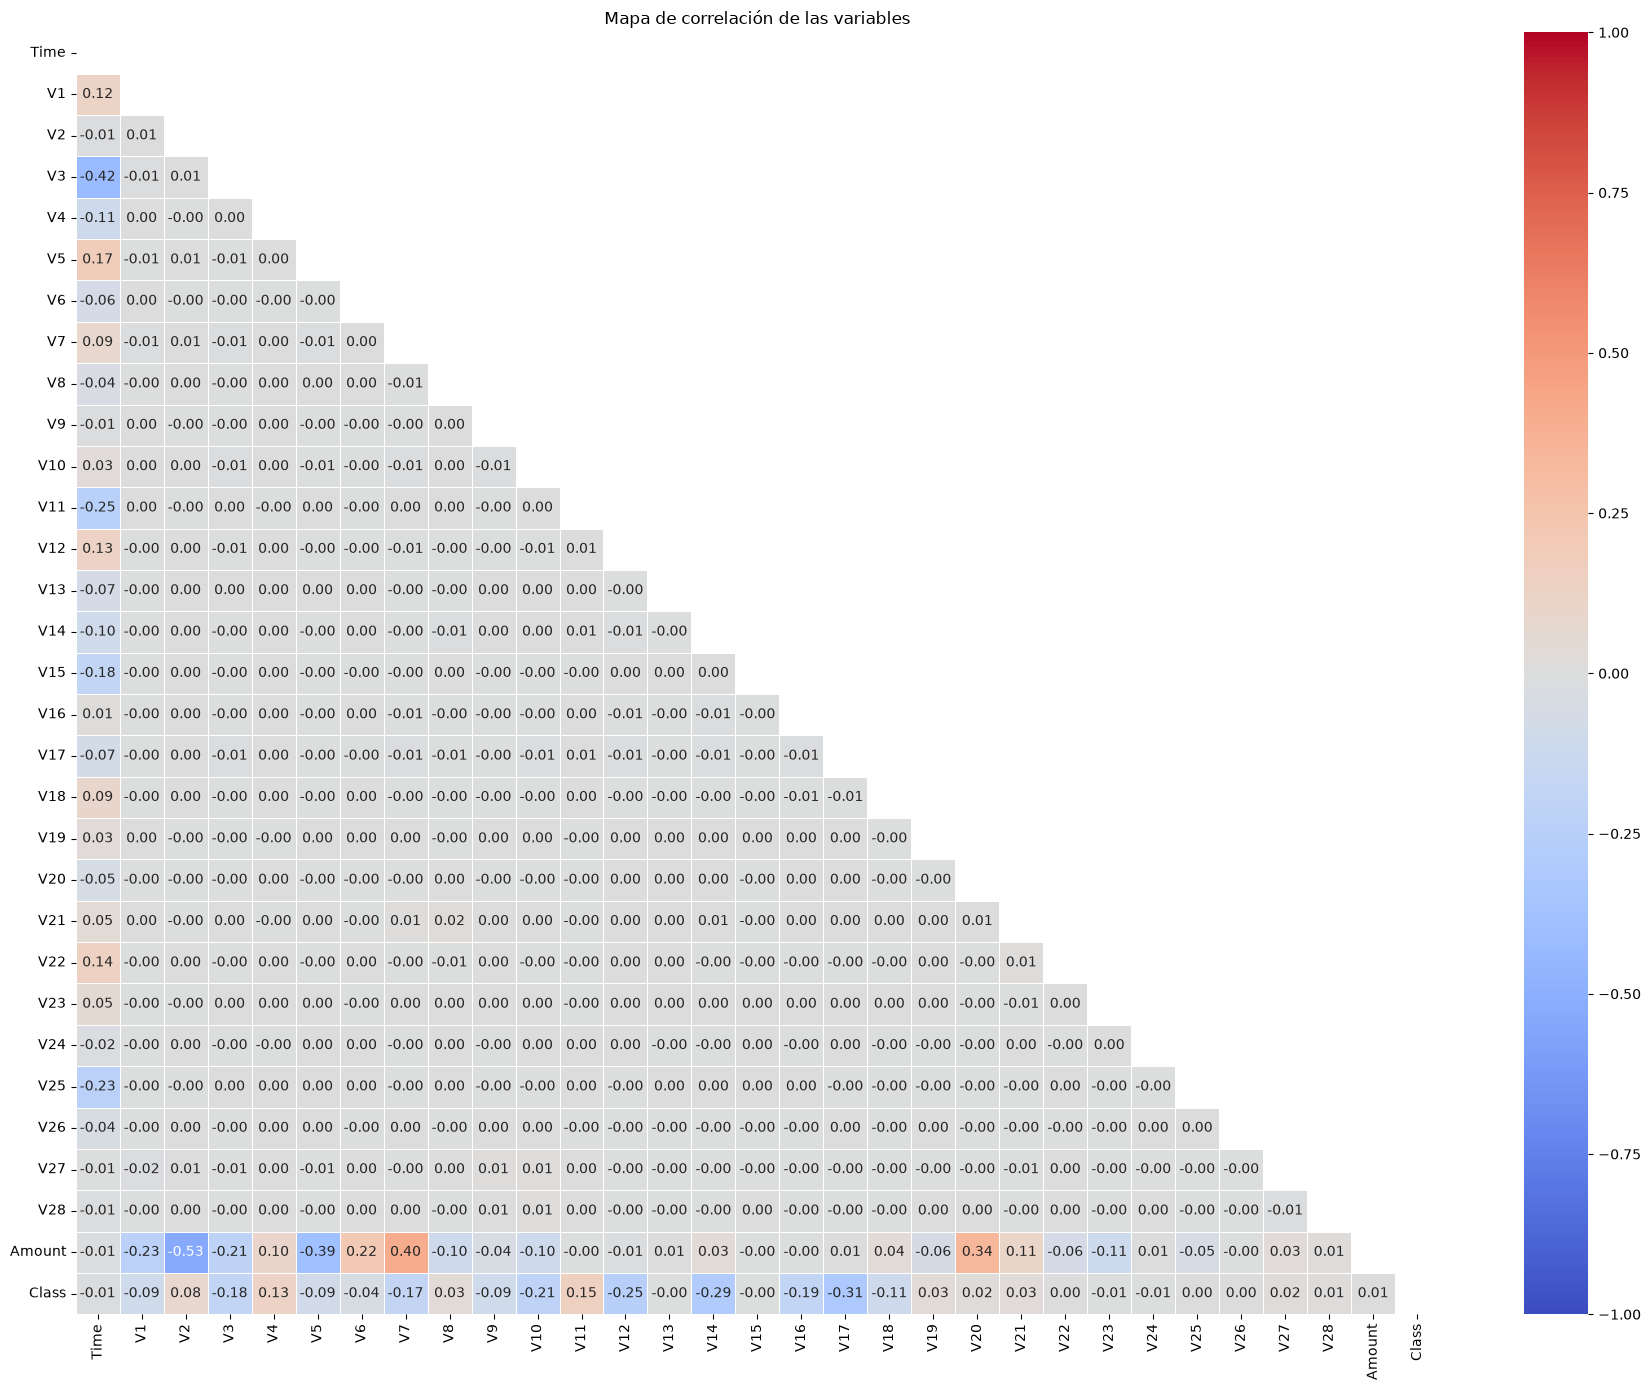

In [10]:
# Mapa de correlación de las variables numéricas, incluida la etiqueta Class
correlaciones = df.select_dtypes(include="number").corr()

plt.figure(figsize=(18, 14))
mascara = np.triu(np.ones_like(correlaciones, dtype=bool))

sns.heatmap(
    correlaciones,
    mask=mascara,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Mapa de correlación de las variables")
plt.tight_layout()
plt.show()

Solamente amount y v2 tienen una correlacion moderada con un valor de -0.53. 


## 5. Aporte de la variable Time


La variable Time se transforma en dos variables, Time_sin y Time_cos, mediante funciones trigonométricas que representan el tiempo de forma cíclica, considerando un período de 24 horas (86 400 segundos). Esto permite evaluar si dicha representación mejora la detección de fraudes frente al uso de Time original o su eliminación.

In [11]:
columnas_base = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount"]
X_original = df[columnas_base].copy()
y = df["Class"]

# Reemplazar Time por su representación cíclica
X_ciclico = X_original.drop(columns="Time").copy()
angulo = 2 * np.pi * (X_original["Time"] % 86400) / 86400
X_ciclico["Time_sin"] = np.sin(angulo)
X_ciclico["Time_cos"] = np.cos(angulo)

# Eliminar Time por completo
X_sin_time = X_original.drop(columns="Time").copy()

# Misma partición para comparar las tres versiones
indices_train, indices_test = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42,
    stratify=y
)
y_train = y.loc[indices_train]
y_test = y.loc[indices_test]

versiones = {
    "Original": X_original,
    "Time_sin_cos": X_ciclico,
    "Sin_Time": X_sin_time
}

modelos_entrenados = {}
resultados_modelos = []

for nombre_version, X_version in versiones.items():
    X_train = X_version.loc[indices_train]
    X_test = X_version.loc[indices_test]

    modelos = {
        "Regresión logística": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, random_state=42)
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),
        "XGBoost": XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )
    }

    for nombre_modelo, modelo in modelos.items():
        modelo.fit(X_train, y_train)

        y_pred = modelo.predict(X_test)
        y_prob = modelo.predict_proba(X_test)[:, 1]

        clave = f"{nombre_version} - {nombre_modelo}"
        modelos_entrenados[clave] = modelo

        resultados_modelos.append({
            "Versión": nombre_version,
            "Modelo": nombre_modelo,
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1-score": f1_score(y_test, y_pred, zero_division=0),
            "PR-AUC": average_precision_score(y_test, y_prob),
            "ROC-AUC": roc_auc_score(y_test, y_prob)
        })

df_comparacion = (
    pd.DataFrame(resultados_modelos)
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)

display(df_comparacion.round(4))

,Versión,Modelo,Precision,Recall,F1-score,PR-AUC,ROC-AUC
0,Original,XGBoost,0.9726,0.7474,0.8452,0.8324,0.9742
1,Time_sin_cos,XGBoost,0.9722,0.7368,0.8383,0.8272,0.9711
2,Sin_Time,XGBoost,0.9589,0.7368,0.8333,0.8243,0.9740
3,Original,Random Forest,0.9722,0.7368,0.8383,0.7995,0.9329
4,Time_sin_cos,Random Forest,0.9726,0.7474,0.8452,0.7982,0.9275
5,Sin_Time,Random Forest,0.9722,0.7368,0.8383,0.7977,0.9483
6,Original,Regresión logística,0.8462,0.5789,0.6875,0.6920,0.9560
7,Sin_Time,Regresión logística,0.8462,0.5789,0.6875,0.6916,0.9557
8,Time_sin_cos,Regresión logística,0.8462,0.5789,0.6875,0.6915,0.9591


Los resultados muestran que la variable Time aporta poco valor predictivo, ya que tanto su uso original como su transformación cíclica mediante Time_sin y Time_cos producen resultados muy similares. Ninguno de los modelos presenta una mejora consistente al conservarla o transformarla, por lo que podría eliminarse para simplificar el análisis sin afectar significativamente el rendimiento de los modelos.

## 6. Comparación sin Time: todas las variables frente a un subconjunto seleccionado

In [12]:
# Comparar los tres modelos usando dos conjuntos de variables, ambos sin Time.
objetivo = df["Class"]
features_todas = [f"V{i}" for i in range(1, 29)] + ["Amount"]
features_seleccionadas = ["V2", "V10", "V11", "V12", "V14", "V17", "V27", "Amount"]

conjuntos_features = {
    "Todas_sin_Time": features_todas,
    "Seleccionadas": features_seleccionadas
}

# Una partición común y estratificada para que la comparación sea justa.
idx_train, idx_test = train_test_split(
    df.index,
    test_size=0.20,
    random_state=42,
    stratify=objetivo
)

resultados_sin_time = []

for nombre_features, columnas in conjuntos_features.items():
    X_train_exp = df.loc[idx_train, columnas]
    X_test_exp = df.loc[idx_test, columnas]
    y_train_exp = objetivo.loc[idx_train]
    y_test_exp = objetivo.loc[idx_test]

    modelos_exp = {
        "Regresión logística": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, random_state=42)
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            n_jobs=-1
        ),
        "XGBoost": XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )
    }

    for nombre_modelo, modelo_exp in modelos_exp.items():
        modelo_exp.fit(X_train_exp, y_train_exp)
        pred = modelo_exp.predict(X_test_exp)
        prob = modelo_exp.predict_proba(X_test_exp)[:, 1]

        resultados_sin_time.append({
            "Variables": nombre_features,
            "Modelo": nombre_modelo,
            "Precision": precision_score(y_test_exp, pred, zero_division=0),
            "Recall": recall_score(y_test_exp, pred, zero_division=0),
            "F1-score": f1_score(y_test_exp, pred, zero_division=0),
            "PR-AUC": average_precision_score(y_test_exp, prob),
            "ROC-AUC": roc_auc_score(y_test_exp, prob)
        })

df_resultados_sin_time = (
    pd.DataFrame(resultados_sin_time)
    .sort_values("PR-AUC", ascending=False)
    .reset_index(drop=True)
)

display(df_resultados_sin_time.round(4))

,Variables,Modelo,Precision,Recall,F1-score,PR-AUC,ROC-AUC
0,Todas_sin_Time,XGBoost,0.9589,0.7368,0.8333,0.8243,0.9740
1,Todas_sin_Time,Random Forest,0.9722,0.7368,0.8383,0.7977,0.9483
2,Seleccionadas,Random Forest,0.9333,0.7368,0.8235,0.7783,0.9174
3,Seleccionadas,XGBoost,0.9333,0.7368,0.8235,0.7712,0.9720
4,Todas_sin_Time,Regresión logística,0.8462,0.5789,0.6875,0.6916,0.9557
5,Seleccionadas,Regresión logística,0.8500,0.5368,0.6581,0.6462,0.9297


Los resultados muestran que la selección de ocho variables predictoras permite mantener un buen rendimiento en la detección de fraudes.

## 7. División de los datos (entrenamiento / prueba)

Se realiza una única partición estratificada del conjunto de datos en entrenamiento (80 %) y prueba (20 %), utilizando la variable objetivo `Class` y una semilla fija para garantizar la reproducibilidad.

El conjunto de prueba permanece intacto y es el mismo que se utiliza en todas las comparaciones anteriores, de modo que los resultados de todas las secciones son comparables entre sí.

In [ ]:
# Variables de entrada (sin Time, segun la comparacion de la seccion anterior)
# y etiqueta objetivo, ambas tomadas directamente del dataframe.
COLUMNAS_MODELO = [f"V{i}" for i in range(1, 29)] + ["Amount"]

X = df[COLUMNAS_MODELO].copy()
y_target = df["Class"]

# Division estratificada 80/20 con semilla fija: garantiza la reproducibilidad
# y conserva clases fraude/no fraude en ambos conjuntos.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_target,
    test_size=0.20,
    random_state=42,
    stratify=y_target
)

# Subconjunto de variables seleccionadas en la seccion anterior.
features_seleccionadas = ["V2", "V10", "V11", "V12", "V14", "V17", "V27", "Amount"]

X_train_sel = X_train[features_seleccionadas]
X_test_sel = X_test[features_seleccionadas]

print("Entrenamiento:", X_train.shape, y_train.value_counts().to_dict())
print("Prueba:", X_test.shape, y_test.value_counts().to_dict())
print("Variables seleccionadas:", features_seleccionadas)

Entrenamiento: (226980, 29) {0: 226602, 1: 378}
Prueba: (56746, 29) {0: 56651, 1: 95}
Variables seleccionadas: ['V2', 'V10', 'V11', 'V12', 'V14', 'V17', 'V27', 'Amount']


## 8. Ajuste de hiperparámetros con validación cruzada

Se busca la mejor configuración de cada modelo sobre el subconjunto de variables seleccionadas mediante `GridSearchCV` con validación cruzada estratificada, optimizando la *average precision* (PR-AUC), la métrica apropiada para conjuntos con clases desbalanceadas. Los mejores modelos se evalúan después sobre el conjunto de prueba.

In [15]:
cv_grid = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
peso_fraude = (y_train == 0).sum() / (y_train == 1).sum()

modelos_grid = {
    "Regresión logística": (
        make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, random_state=42)
        ),
        {
            "logisticregression__C": [0.1, 1, 10],
            "logisticregression__class_weight": [None, "balanced"]
        }
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {
            "n_estimators": [200],
            "max_depth": [None, 12],
            "min_samples_leaf": [1, 3],
            "class_weight": [None, "balanced_subsample"]
        }
    ),
    "XGBoost": (
        XGBClassifier(
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=1
        ),
        {
            "n_estimators": [200, 400],
            "max_depth": [3, 5],
            "learning_rate": [0.05, 0.1],
            "scale_pos_weight": [1, peso_fraude]
        }
    )
}

busquedas_grid = {}
mejores_modelos_grid = {}
resultados_grid = []

for nombre, (estimador, parametros) in modelos_grid.items():
    busqueda = GridSearchCV(
        estimator=estimador,
        param_grid=parametros,
        scoring="average_precision",
        cv=cv_grid,
        n_jobs=-1,
        refit=True,
        verbose=1
    )

    busqueda.fit(X_train_sel, y_train)
    busquedas_grid[nombre] = busqueda
    mejores_modelos_grid[nombre] = busqueda.best_estimator_

    y_prob = busqueda.best_estimator_.predict_proba(X_test_sel)[:, 1]
    y_pred = busqueda.best_estimator_.predict(X_test_sel)

    resultados_grid.append({
        "Modelo": nombre,
        "Mejores parámetros": busqueda.best_params_,
        "PR-AUC CV": busqueda.best_score_,
        "PR-AUC prueba": average_precision_score(y_test, y_prob),
        "ROC-AUC prueba": roc_auc_score(y_test, y_prob),
        "Precision prueba": precision_score(y_test, y_pred, zero_division=0),
        "Recall prueba": recall_score(y_test, y_pred, zero_division=0),
        "F1 prueba": f1_score(y_test, y_pred, zero_division=0)
    })

df_resultados_grid = (
    pd.DataFrame(resultados_grid)
    .sort_values("PR-AUC prueba", ascending=False)
    .reset_index(drop=True)
)

# Metricas
display(
    df_resultados_grid.drop(columns=["Mejores parámetros"]).round(4)
)

# Parametros
for _, fila in df_resultados_grid.iterrows():
    print(f"\n{fila['Modelo']}")
    for parametro, valor in fila["Mejores parámetros"].items():
        print(f"  {parametro}: {valor}")

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Fitting 5 folds for each of 16 candidates, totalling 80 fits


,Modelo,PR-AUC CV,PR-AUC prueba,ROC-AUC prueba,Precision prueba,Recall prueba,F1 prueba
0,Random Forest,0.8347,0.7750,0.9629,0.9211,0.7368,0.8187
1,XGBoost,0.8184,0.7634,0.9675,0.9079,0.7263,0.8070
2,Regresión logística,0.7275,0.6438,0.9300,0.8500,0.5368,0.6581



Random Forest
  class_weight: None
  max_depth: 12
  min_samples_leaf: 1
  n_estimators: 200

XGBoost
  learning_rate: 0.05
  max_depth: 3
  n_estimators: 200
  scale_pos_weight: 1

Regresión logística
  logisticregression__C: 0.1
  logisticregression__class_weight: None


## 9. Conclusiones


| Modelo | PR-AUC antes | PR-AUC ajustado | F1 antes | F1 ajustado |
|---|---:|---:|---:|---:|
| Random Forest | 0.7783 | 0.7750 | 0.8235 | 0.8187 |
| XGBoost | 0.7712 | 0.7634 | 0.8235 | 0.8070 |
| Regresión logística | 0.6462 | 0.6438 | 0.6581 | 0.6581 |

La reducción de características de 30 a 8 variables permitió simplificar los modelos, manteniendo un desempeño competitivo en la detección de transacciones fraudulentas. Antes del ajuste de hiperparámetros, Random Forest obtuvo el mejor resultado, con un PR-AUC de 0.7783 y un F1 de 0.8235, mientras que XGBoost alcanzó el mismo F1. Después del ajuste, Random Forest se mantuvo como la mejor alternativa, con un PR-AUC de prueba de 0.7750 y un F1 de 0.8187. XGBoost presentó valores de 0.7634 y 0.8070, respectivamente, mientras que la regresión logística mostró un desempeño inferior.

En general, el ajuste de hiperparámetros no produjo mejoras en las métricas de prueba, sino pequeñas disminuciones en Random Forest y XGBoost, mientras que la regresión logística mantuvo su F1. Estos resultados sugieren que la selección de ocho características conserva buena parte de la capacidad predictiva de los modelos, aunque para cuantificar el efecto de reducir de 30 a 8 variables sería necesario compararlos con los modelos entrenados utilizando las 30 características bajo las mismas condiciones